# Resolución patentes — Benja — Opción B: verificación por contornos
Agrega una segunda opinión con `findContours` (agujeros y solidez) y variantes artificiales. No usa imágenes externas.

In [1]:
import os, sys
import cv2
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("."))
import modelo_benja as M

P = M.P          # patentes.py original, sin cambios

SALIDA = os.path.join(M.RAIZ, "images", "resolucion_patentes_benja_opcion_b")
tp = M.cargar_tp()
base = {i: P.analizar_foto(M.ruta_foto(i)) for i in M.FOTOS}

## Parte 1 — Firma de contornos
Cada carácter se agranda y se buscan sus contornos: un contorno dentro de otro es un agujero (en verde). La solidez es el área sobre el área del casco convexo.

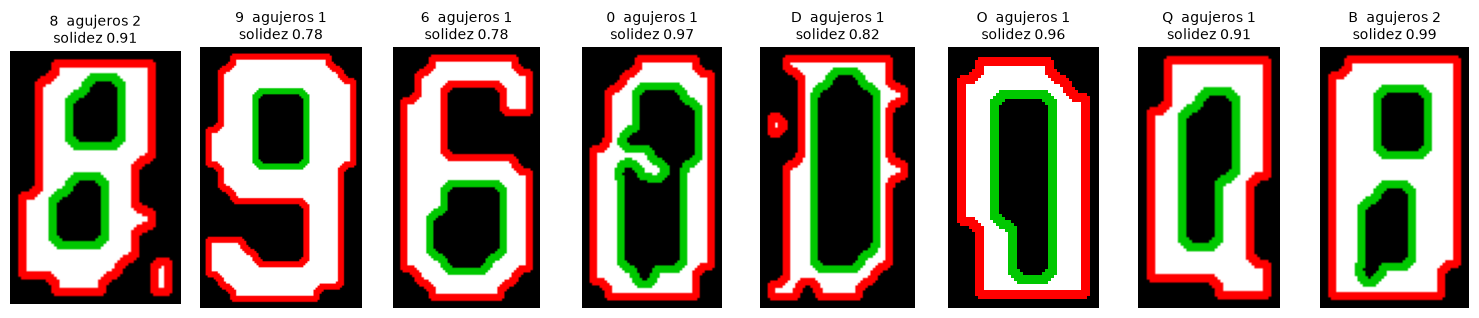

In [2]:
def dibujar(caracter):
    g = cv2.resize(caracter, None, fx=6, fy=6, interpolation=cv2.INTER_CUBIC)
    g = cv2.threshold(cv2.copyMakeBorder(g, 4, 4, 4, 4, cv2.BORDER_CONSTANT, value=0), 127, 255, cv2.THRESH_BINARY)[1]
    cs, jer = cv2.findContours(g, cv2.RETR_CCOMP, cv2.CHAIN_APPROX_SIMPLE)
    vis = cv2.cvtColor(g, cv2.COLOR_GRAY2BGR)
    for c, j in zip(cs, jer[0]):
        cv2.drawContours(vis, [c], -1, (0, 200, 0) if j[3] != -1 else (0, 0, 255), 2)
    return cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)

ejemplos = [(2, 5), (6, 3), (9, 4), (3, 3), (3, 0), (7, 1), (2, 2), (1, 0)]      # 8, 9, 6, 0, D, O, Q, B
fig, ejes = plt.subplots(1, len(ejemplos), figsize=(15, 3.2))
for e, (i, p) in zip(ejes, ejemplos):
    f = M.firma_contornos(tp[i]["caracteres"][p])
    e.imshow(dibujar(tp[i]["caracteres"][p])); e.axis("off")
    e.set_title(f"{M.ETIQUETAS[i][p]}  agujeros {f['n']}\nsolidez {f['solidez']:.2f}", fontsize=10)
plt.tight_layout(); plt.show()

## Parte 2 — Reglas de compatibilidad
`desajuste` cuenta las reglas que no se cumplen entre un carácter y una referencia: distinta cantidad de agujeros, agujero a otra altura (9 arriba, 0 al medio, 6 abajo) y forma recta de un lado (D) contra redonda (O).
La distancia final es la distancia entre huellas más 2 × el desajuste.

In [3]:
PESO = 2.0
configs = {"huellas solas":                  (M.armar_referencias(tp), 0),
           "solo contornos":                 (M.armar_referencias(tp), PESO),
           "solo variantes":                 (M.armar_referencias(tp, (), aumentar=True), 0),
           "variantes + contornos (opción B)": (M.armar_referencias(tp, (), aumentar=True), PESO)}
resultados = {nombre: M.evaluar(tp, refs, peso) for nombre, (refs, peso) in configs.items()}
for nombre, (_, res) in resultados.items():
    print(f"{nombre:<34} letras {res['letras']:>2}/36   números {res['numeros']:>2}/36   completas {res['completas']:>2}/12")

huellas solas                      letras 24/36   números 29/36   completas  0/12
solo contornos                     letras 28/36   números 33/36   completas  4/12
solo variantes                     letras 27/36   números 31/36   completas  3/12
variantes + contornos (opción B)   letras 31/36   números 33/36   completas  7/12


## Parte 3 — Sensibilidad al peso
Repite la opción B con otros pesos para ver que no depende de un valor exacto.

In [4]:
refs = M.armar_referencias(tp, (), aumentar=True)
for peso in (0, 0.5, 1, 2, 5, 10):
    res = M.evaluar(tp, refs, peso)[1]
    print(f"peso {peso:<4} letras {res['letras']:>2}/36   números {res['numeros']:>2}/36   completas {res['completas']:>2}/12")

peso 0    letras 27/36   números 31/36   completas  3/12
peso 0.5  letras 29/36   números 34/36   completas  5/12
peso 1    letras 30/36   números 35/36   completas  6/12
peso 2    letras 31/36   números 33/36   completas  7/12


peso 5    letras 31/36   números 33/36   completas  7/12
peso 10   letras 31/36   números 33/36   completas  7/12


## Parte 4 — Resultado por patente
Guarda una imagen por patente y un `resumen.csv` en `images/resolucion_patentes_benja_opcion_b/`.

In [5]:
lecturas, res = resultados["variantes + contornos (opción B)"]
for i in M.FOTOS:
    print(f"img{i:02d}  leída {lecturas[i]}  real {M.ETIQUETAS[i]}  {res['aciertos'][i]}/6")
M.guardar_resultados(SALIDA, tp, base, lecturas, "   |   opción B")
print(f"\nletras {res['letras']}/36   números {res['numeros']}/36   patentes completas {res['completas']}/12")
print("meta de 7/12:", "cumplida" if res["completas"] >= 7 else "no cumplida")
print("guardado en", SALIDA)

img01  leída BHF817  real BUF817  5/6
img02  leída GXQ798  real GXQ798  6/6
img03  leída DMH424  real DMH024  5/6
img04  leída LHE986  real LHE986  6/6
img05  leída FJX300  real FJY344  3/6
img06  leída LEH992  real LEH992  6/6
img07  leída LOD123  real LOD123  6/6
img08  leída JMO337  real JMO337  6/6
img09  leída FFD765  real FFD765  6/6
img10  leída DQD322  real DOA322  4/6
img11  leída GMO569  real GMQ569  5/6
img12  leída BQX387  real BQX387  6/6



letras 31/36   números 33/36   patentes completas 7/12
meta de 7/12: cumplida
guardado en C:\Users\Benja\Documents\Facultad\3\cuatri_dos\imagenes\tp_procesamiento_de_imagenes_2\images\resolucion_patentes_benja_opcion_b
